# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

# Funkcije

In [2]:
def aktivacija(z, ime, odvod=False):
    """Aktivacijske funkcije in njihovi odvodi."""
    z = np.asarray(z, float)
    if ime == "tanh":
        return 1 - np.tanh(z)**2 if odvod else np.tanh(z)
    if ime == "sigmoid":
        s = 1 / (1 + np.exp(-z))
        return s * (1 - s) if odvod else s
    if ime == "relu":
        return (z > 0).astype(float) if odvod else np.maximum(0, z)
    if ime == "linear":
        return np.ones_like(z) if odvod else z
    raise ValueError(ime)


def ustvari_mrezo(arhitektura, rng=rng):
    """Seznam parov (W, b) za arhitekturo, npr. [2, 8, 1]. Uteži ~ N(0, 1/n_vhod) (Xavier)."""
    return [(rng.normal(0, 1 / np.sqrt(n_in), (n_in, n_out)), np.zeros(n_out))
            for n_in, n_out in zip(arhitektura[:-1], arhitektura[1:])]


def naprej(mreza, X, aktivacije):
    """Propagacija naprej za paket vhodov X (N, n_vhod). Vrne seznama z (pred aktivacijo) in a (po njej);
    a[0] = X, a[-1] je izhod mreže."""
    zs, As = [], [X]
    for (W, b), f in zip(mreza, aktivacije):
        z = As[-1] @ W + b
        zs.append(z)
        As.append(aktivacija(z, f))
    return zs, As


def izguba(y, y_nap, ime="MSE"):
    """Izguba in njen odvod po izhodu mreže (povprečje po vzorcih)."""
    N = len(y)
    if ime == "MSE":
        return np.mean((y_nap - y)**2), 2 * (y_nap - y) / (N * y.shape[1])
    if ime == "BCE":     # binarna navzkrižna entropija (izhod s sigmoido)
        p = np.clip(y_nap, 1e-12, 1 - 1e-12)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)), (p - y) / (p * (1 - p)) / N
    raise ValueError(ime)


def nazaj(mreza, zs, As, dL_da, aktivacije):
    """Vzvratno razširjanje napake. Vrne seznam gradientov (dW, db) za vse plasti."""
    grad = [None] * len(mreza)
    delta = dL_da * aktivacija(zs[-1], aktivacije[-1], odvod=True)
    for l in reversed(range(len(mreza))):
        grad[l] = (As[l].T @ delta, delta.sum(axis=0))
        if l > 0:
            delta = (delta @ mreza[l][0].T) * aktivacija(zs[l - 1], aktivacije[l - 1], odvod=True)
    return grad


def uci(mreza, X, y, aktivacije, eta=0.1, epohe=2000, ime_izgube="MSE", X_test=None, y_test=None):
    """Gradientni spust na celotnem paketu. Vrne zgodovino izgube (učna, testna)."""
    zg_u, zg_t = [], []
    for ep in range(epohe):
        zs, As = naprej(mreza, X, aktivacije)
        L, dL = izguba(y, As[-1], ime_izgube)
        grad = nazaj(mreza, zs, As, dL, aktivacije)
        mreza[:] = [(W - eta * dW, b - eta * db) for (W, b), (dW, db) in zip(mreza, grad)]
        zg_u.append(L)
        if X_test is not None:
            zg_t.append(izguba(y_test, naprej(mreza, X_test, aktivacije)[1][-1], ime_izgube)[0])
    return np.array(zg_u), np.array(zg_t)


def numericni_gradient(mreza, X, y, aktivacije, h=1e-6):
    """Gradient izgube MSE po vseh utežeh s centralnimi diferencami (za preverjanje)."""
    grad = []
    for W, b in mreza:
        gW, gb = np.zeros_like(W), np.zeros_like(b)
        for P, G in ((W, gW), (b, gb)):
            for idx in np.ndindex(P.shape):
                staro = P[idx]
                P[idx] = staro + h
                Lp = izguba(y, naprej(mreza, X, aktivacije)[1][-1])[0]
                P[idx] = staro - h
                Lm = izguba(y, naprej(mreza, X, aktivacije)[1][-1])[0]
                P[idx] = staro
                G[idx] = (Lp - Lm) / (2 * h)
        grad.append((gW, gb))
    return grad

# Testno območje

In [3]:
# P1: vrednosti pri z = 0
print({f: (float(aktivacija(0.0, f)), float(aktivacija(0.0, f, True))) for f in ("tanh", "sigmoid", "relu", "linear")})

# P3: en nevron s sigmoido
mreza_p3 = [(np.array([[0.5], [-1.0]]), np.array([0.2]))]
zs, As = naprej(mreza_p3, np.array([[1.0, 2.0]]), ["sigmoid"])
L, dL = izguba(np.array([[1.0]]), As[-1])
g = nazaj(mreza_p3, zs, As, dL, ["sigmoid"])
print(f"P3: z = {zs[0][0, 0]:.3f}, a = {As[-1][0, 0]:.4f}, L = {L:.4f}, dL/dw = {g[0][0].ravel().round(4)}, dL/db = {g[0][1].round(4)}")

# P2: število parametrov
for arh in ([1, 10, 1], [2, 8, 1], [2, 2, 1]):
    print(arh, "parametrov:", sum(W.size + b.size for W, b in ustvari_mrezo(arh)))

{'tanh': (0.0, 1.0), 'sigmoid': (0.5, 0.25), 'relu': (0.0, 0.0), 'linear': (0.0, 1.0)}
P3: z = -1.300, a = 0.2142, L = 0.6175, dL/dw = [-0.2645 -0.529 ], dL/db = [-0.2645]
[1, 10, 1] parametrov: 31
[2, 8, 1] parametrov: 33
[2, 2, 1] parametrov: 9


# Naloga 1 - Slika 1

tanh    : max |numerični - analitični odvod| = 1.3e-05 (mediana), 1.3e-04 (max)
sigmoid : max |numerični - analitični odvod| = 2.4e-06 (mediana), 8.3e-06 (max)
relu    : max |numerični - analitični odvod| = 0.0e+00 (mediana), 5.0e-01 (max)
linear  : max |numerični - analitični odvod| = 0.0e+00 (mediana), 1.4e-14 (max)


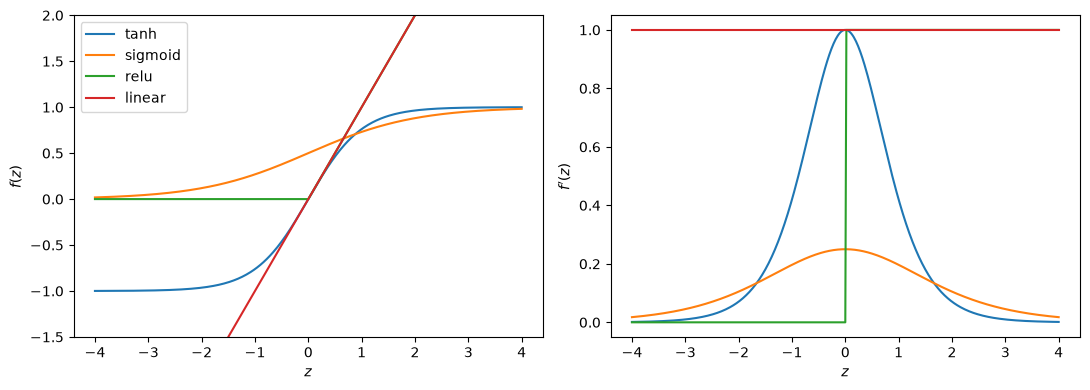

In [4]:
z = np.linspace(-4, 4, 401)
fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
for f in ("tanh", "sigmoid", "relu", "linear"):
    ax1.plot(z, aktivacija(z, f), label=f)
    ax2.plot(z, aktivacija(z, f, True), label=f)
    napaka = np.abs(np.gradient(aktivacija(z, f), z) - aktivacija(z, f, True))[1:-1]
    print(f"{f:8s}: max |numerični - analitični odvod| = {np.median(napaka):.1e} (mediana), {napaka.max():.1e} (max)")
ax1.set_xlabel("$z$")
ax1.set_ylabel("$f(z)$")
ax1.set_ylim(-1.5, 2)
ax1.legend()
ax2.set_xlabel("$z$")
ax2.set_ylabel("$f'(z)$")
fig.tight_layout()
plt.show()

# Naloga 2

In [5]:
# Preverjanje gradienta na majhni mreži [2, 3, 1]
X_g = rng.normal(size=(5, 2))
y_g = rng.normal(size=(5, 1))
akt_g = ["tanh", "linear"]
mreza_g = ustvari_mrezo([2, 3, 1])
zs, As = naprej(mreza_g, X_g, akt_g)
g_bp = nazaj(mreza_g, zs, As, izguba(y_g, As[-1])[1], akt_g)
g_num = numericni_gradient(mreza_g, X_g, y_g, akt_g)
for l, ((dW, db), (nW, nb)) in enumerate(zip(g_bp, g_num)):
    rel = np.linalg.norm(dW - nW) / np.linalg.norm(dW + nW)
    print(f"plast {l}: |dW| = {np.linalg.norm(dW):.4f}, rel. napaka dW = {rel:.1e}, "
          f"rel. napaka db = {np.linalg.norm(db - nb) / np.linalg.norm(db + nb):.1e}")

plast 0: |dW| = 0.4524, rel. napaka dW = 1.5e-10, rel. napaka db = 6.3e-11
plast 1: |dW| = 0.4098, rel. napaka dW = 8.1e-11, rel. napaka db = 4.3e-11


# Naloga 3 - Slika 2

eta = 0.01: MSE učna = 0.2071, testna = 0.1978
eta = 0.05: MSE učna = 0.0132, testna = 0.0077
eta = 0.2: MSE učna = 0.0211, testna = 0.0228


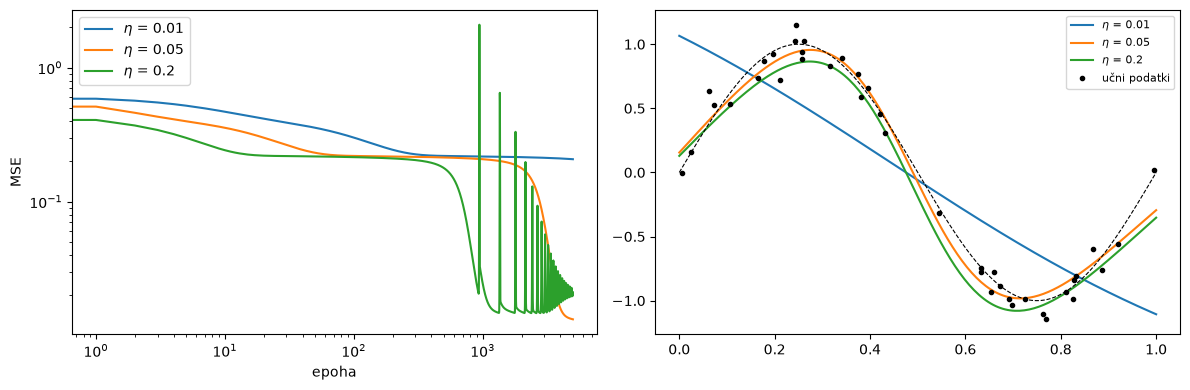

In [6]:
# Regresija: y = sin(2 pi x) + šum
x_u = rng.uniform(0, 1, (40, 1))
y_u = np.sin(2 * np.pi * x_u) + rng.normal(0, 0.1, x_u.shape)
x_t = np.linspace(0, 1, 200)[:, None]
y_t = np.sin(2 * np.pi * x_t)
akt = ["tanh", "linear"]
fig = plt.figure(figsize=(12, 4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
for eta in (0.01, 0.05, 0.2):
    m = ustvari_mrezo([1, 10, 1], rng=np.random.default_rng(0))
    L_u, L_t = uci(m, x_u, y_u, akt, eta=eta, epohe=5000, X_test=x_t, y_test=y_t)
    ax1.loglog(L_u, label=f"$\\eta$ = {eta}")
    ax2.plot(x_t, naprej(m, x_t, akt)[1][-1], label=f"$\\eta$ = {eta}")
    print(f"eta = {eta}: MSE učna = {L_u[-1]:.4f}, testna = {L_t[-1]:.4f}")
ax2.plot(x_u, y_u, "k.", label="učni podatki")
ax2.plot(x_t, y_t, "k--", lw=0.8)
ax1.set_xlabel("epoha")
ax1.set_ylabel("MSE")
ax1.legend()
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [7]:
# Preglednica 3 (nadaljevanje): vpliv števila skritih nevronov (eta = 0.05)
for n_skr in (1, 3, 10, 30):
    m = ustvari_mrezo([1, n_skr, 1], rng=np.random.default_rng(0))
    L_u, L_t = uci(m, x_u, y_u, akt, eta=0.05, epohe=5000, X_test=x_t, y_test=y_t)
    print(f"skritih = {n_skr:2d}: parametrov = {3*n_skr+1}, MSE učna = {L_u[-1]:.4f}, testna = {L_t[-1]:.4f}")

skritih =  1: parametrov = 4, MSE učna = 0.0932, testna = 0.0966
skritih =  3: parametrov = 10, MSE učna = 0.0227, testna = 0.0193
skritih = 10: parametrov = 31, MSE učna = 0.0132, testna = 0.0077
skritih = 30: parametrov = 91, MSE učna = 0.0260, testna = 0.0221


# Naloga 4 - Slika 3

skritih = 1: BCE = 0.573, točnost = 0.672
skritih = 2: BCE = 0.382, točnost = 0.833
skritih = 4: BCE = 0.016, točnost = 1.000
skritih = 8: BCE = 0.004, točnost = 1.000


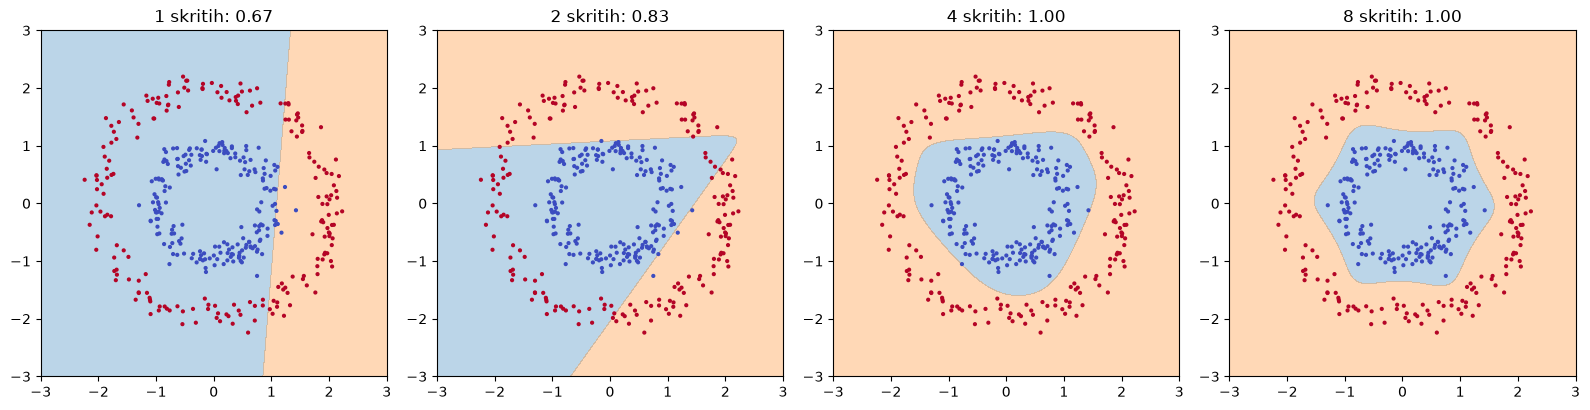

In [8]:
# Klasifikacija: dva koncentrična obroča
N = 200
r = np.r_[rng.normal(1.0, 0.15, N), rng.normal(2.0, 0.15, N)]
fi = rng.uniform(0, 2 * np.pi, 2 * N)
X_k = np.column_stack([r * np.cos(fi), r * np.sin(fi)])
y_k = np.r_[np.zeros(N), np.ones(N)][:, None]
akt_k = ["tanh", "sigmoid"]
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
mreza_tocke = np.column_stack([xx.ravel(), yy.ravel()])
fig = plt.figure(figsize=(16, 4))
for k, n_skr in enumerate((1, 2, 4, 8)):
    m = ustvari_mrezo([2, n_skr, 1], rng=np.random.default_rng(0))
    L_u, _ = uci(m, X_k, y_k, akt_k, eta=1.0, epohe=3000, ime_izgube="BCE")
    p = naprej(m, X_k, akt_k)[1][-1]
    tocnost = np.mean((p > 0.5) == (y_k > 0.5))
    print(f"skritih = {n_skr}: BCE = {L_u[-1]:.3f}, točnost = {tocnost:.3f}")
    ax = fig.add_subplot(1, 4, k + 1)
    P = naprej(m, mreza_tocke, akt_k)[1][-1].reshape(xx.shape)
    ax.contourf(xx, yy, P, levels=[0, 0.5, 1], colors=["tab:blue", "tab:orange"], alpha=0.3)
    ax.scatter(X_k[:, 0], X_k[:, 1], c=y_k.ravel(), cmap="coolwarm", s=4)
    ax.set_title(f"{n_skr} skritih: {tocnost:.2f}")
    ax.set_aspect("equal")
fig.tight_layout()
plt.show()